# KW-PINN Rating Curve Prediction (CONUS)

This notebook **only runs prediction** with an already-trained `RatingCurvePINN` model. It does not retrain anything and does not need the observed-discharge database used for training.

## What you need to run this

1. **Trained model weights** — a `.pth` file, produced by the training notebook.
2. **Fitted feature scaler** — the matching `.pkl` file, a `sklearn.preprocessing.StandardScaler` fitted on the same 6 predictors during training. It must be paired with the model above (same version).
3. **Six predictor GeoTIFF rasters**, all on the same grid (same shape / transform / CRS):
   - `Area_px` — basin (drainage) area
   - `P_mmy_avg` — average annual precipitation (mm/yr)
   - `rr_SH_px` — relief ratio
   - `T_c_avg` — average temperature (°C)
   - `AI` — aridity index
   - `manning500` — Manning's roughness coefficient
4. **A mask raster** (e.g. a flow-accumulation grid) used to restrict prediction to channel pixels, plus a threshold value.

Compatible with the **v22 direct-alpha** training notebook (`KW_PINN_v22_alpha.ipynb`, model folder `KW_PINN_MODEL_v10`): the network outputs α directly (softplus) and β bounded to `[BETA_MIN, BETA_MAX]` (sigmoid), so no `exp` is applied after prediction.

The model predicts the two parameters of the power-law rating curve:

**A = α · Q^β**

where `A` is cross-sectional/wetted area (m²) and `Q` is discharge (m³/s).

> Edit the paths in the **Configuration** cell below, then run all cells.

In [1]:
import pickle
from datetime import datetime
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import rasterio

## 1. Configuration — edit these paths

If you haven't copied the CONUS model/scaler files to this machine yet, copy them from the training environment (originally saved under `models/` relative to the training notebook) into a local folder and update `MODEL_PATH` / `SCALER_PATH` below.


In [2]:
# Notebooks have no __file__; use the folder the notebook is run from
WORKING_DIR = Path.cwd()

# --- Trained model + scaler (must be a matching pair from training) ---
MODEL_DIR = WORKING_DIR / "models"
MODEL_PATH  = MODEL_DIR / "KW_PINN_FL_v02_model.pth"
SCALER_PATH = MODEL_DIR / "KW_PINN_FL_v02_scaler.pkl"

MODEL_PATH  = MODEL_DIR / "KW_PINN_CONUS_v1.10_model.pth"
SCALER_PATH = MODEL_DIR / "KW_PINN_CONUS_v1.10_scaler.pkl"

# --- Beta bounds: must be the same values used in training (v22: 0.3 - 1.0) ---
BETA_MIN = 0.3
BETA_MAX = 1.0

# --- Predictor rasters (must all share the same grid: shape, transform, CRS) ---
PREDICTOR_DIR = WORKING_DIR / "predictors"

# --- Mask raster: prediction only runs where mask > MASK_THRESHOLD ---
MASK_PATH = WORKING_DIR / "basic" / "FAM.tif"
MASK_THRESHOLD = 50

OUTPUT_DIR = WORKING_DIR / "parameters"

# --- Output raster options ---
OUT_NODATA  = -9999        # NaN pixels are written as this value
OUT_BIGTIFF = "IF_SAFER"   # "IF_SAFER" = BigTIFF only if the file could exceed 4 GB; "YES" to force; "NO" to disable
OUT_AUTHOR  = "Santiago Henao"

In [3]:
RASTER_PATHS = {
    "Area_px":    PREDICTOR_DIR / "basin.area.tif",
    "P_mmy_avg":  PREDICTOR_DIR / "wc2.1_30s_prec_mm-y.tif.avg.tif",
    "rr_SH_px":   PREDICTOR_DIR / "relief.ratio.tif",
    "T_c_avg":    PREDICTOR_DIR / "wc2.1_30s_tavg_c.tif.avg.tif",
    "AI":         PREDICTOR_DIR / "ai_v3_yr.tif",
    "manning500": PREDICTOR_DIR / "Global_manning_n_300m.tif",
}

# Order must match the order the scaler/model were trained with
PREDICTORS = ["Area_px", "P_mmy_avg", "rr_SH_px", "T_c_avg", "AI", "manning500"]

# --- Outputs ---
OUT_ALPHA_PATH = OUTPUT_DIR / "KW_alpha.tif"
OUT_BETA_PATH  = OUTPUT_DIR / "KW_beta.tif"

## 2. Model definition

This class must match the architecture used during training exactly, so the saved `state_dict` loads correctly.


In [4]:
class RatingCurvePINN(nn.Module):
    # Same architecture and output transform as KW_PINN_v22_alpha.ipynb
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2),  # alpha_2 (direct, via softplus), beta_2 (bounded sigmoid)
        )

    def forward(self, x):
        out = self.net(x)
        alpha = nn.functional.softplus(out[:, 0:1]) + 1e-6
        beta = BETA_MIN + (BETA_MAX - BETA_MIN) * torch.sigmoid(out[:, 1:2])
        return torch.cat([alpha, beta], dim=1)

## 3. Raster I/O helpers

Lightweight `rasterio`-based replacement for the original `ReadGrid` / `WriteGrid` helpers, so this notebook has no dependency on the training environment's helper module.


In [5]:
def read_grid(path, keep_profile=False):
    with rasterio.open(path) as src:
        arr = src.read(1).astype(np.float32)
        if src.nodata is not None:
            arr = np.where(arr == src.nodata, np.nan, arr)
        profile = src.profile if keep_profile else None
    return (arr, profile) if keep_profile else arr


def write_grid(path, arr, profile, nodata=OUT_NODATA, bigtiff=OUT_BIGTIFF,
               band_name=None, tags=None, band_tags=None):
    out_profile = profile.copy()
    for k in ("blockxsize", "blockysize"):      # avoid conflicts with tiled=False
        out_profile.pop(k, None)
    out_profile.update(
        driver="GTiff",
        dtype="float32",
        count=1,
        nodata=nodata,
        compress="LZW",
        predictor=3,          # floating-point predictor -> better LZW compression
        bigtiff=bigtiff,
        tiled=False,
        interleave="pixel",
    )

    data = np.where(np.isfinite(arr), arr, nodata).astype(np.float32)   # NaN -> nodata

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(path, "w", **out_profile) as dst:
        dst.write(data, 1)
        if band_name:
            dst.set_band_description(1, band_name)
        if tags:
            dst.update_tags(**tags)          # file-level metadata
        if band_tags:
            dst.update_tags(1, **band_tags)  # band-level metadata

## 4. Load model, scaler, and predictor rasters


In [6]:
# --- Load model ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RatingCurvePINN(input_dim=len(PREDICTORS))
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
model.to(device)

# --- Load scaler ---
with SCALER_PATH.open("rb") as f:
    scaler = pickle.load(f)

print("Model and scaler loaded.")


Model and scaler loaded.


c:\Users\henaogomez\AppData\Local\miniconda3\envs\IBM\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [7]:
# --- Read mask and determine valid (channel) pixels ---
mask_grid, ref_profile = read_grid(MASK_PATH, keep_profile=True)
mask = mask_grid > MASK_THRESHOLD
mask_flat = mask.flatten()

# --- Read each predictor raster, keeping only masked pixels ---
def read_and_mask(path):
    return read_grid(path).flatten()[mask_flat]

predictor_arrays = [read_and_mask(RASTER_PATHS[name]) for name in PREDICTORS]
X_masked = np.column_stack(predictor_arrays)

# Clean non-finite / sentinel values
X_masked = np.where(np.isfinite(X_masked) & (np.abs(X_masked) < 1e10), X_masked, np.nan)

# Drop pixels where any predictor is missing
valid_mask = ~np.isnan(X_masked).any(axis=1)
X_clean = X_masked[valid_mask]

print(f"Pixels in mask: {mask_flat.sum()}, valid for prediction: {len(X_clean)}")


Pixels in mask: 247300, valid for prediction: 247300


## 5. Predict α and β

In [8]:
X_scaled = scaler.transform(X_clean)
X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)

with torch.no_grad():
    pred = model(X_tensor).cpu().numpy()

# v22 model returns alpha directly -> no np.exp
alpha_2 = pred[:, 0]
beta_2 = pred[:, 1]

print(f"alpha_2: min {np.nanmin(alpha_2):.3f} | median {np.nanmedian(alpha_2):.3f} | max {np.nanmax(alpha_2):.3f}")
print(f"beta_2 : min {np.nanmin(beta_2):.3f} | median {np.nanmedian(beta_2):.3f} | max {np.nanmax(beta_2):.3f}")

alpha_2: min 2.295 | median 2.547 | max 3.906
beta_2 : min 0.739 | median 0.748 | max 0.779


c:\Users\henaogomez\AppData\Local\miniconda3\envs\IBM\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 6. Write output rasters


In [9]:
# Rebuild full-size grids (NaN outside the valid/masked pixels)
alpha_full = np.full(mask_flat.shape, np.nan, dtype=np.float32)
beta_full = np.full(mask_flat.shape, np.nan, dtype=np.float32)

final_positions = mask_flat.copy()
final_positions[mask_flat] = valid_mask

alpha_full[final_positions] = alpha_2
beta_full[final_positions] = beta_2

alpha_grid = alpha_full.reshape(mask_grid.shape)
beta_grid = beta_full.reshape(mask_grid.shape)

common_tags = {
    "LAYER_NAME": "KW-PINN rating curve parameter, A = alpha * Q^beta (A in m2, Q in m3/s)",
    "MODEL": f"{MODEL_PATH.name}",
    "MASK": f"{MASK_PATH.name} > {MASK_THRESHOLD}",
}

write_grid(OUT_ALPHA_PATH, alpha_grid, ref_profile,
           band_name="alpha_2",
           tags={**common_tags, "PARAMETER": "alpha (KW coefficient)"})

write_grid(OUT_BETA_PATH, beta_grid, ref_profile,
           band_name="beta_2",
           tags={**common_tags, "PARAMETER": "beta (KW exponent)"})

print(f"Wrote: {OUT_ALPHA_PATH}")
print(f"Wrote: {OUT_BETA_PATH}")

Wrote: c:\Users\henaogomez\OneDrive\1_ESTUDIO\3_MAESTRIA_UI\0_CONFERENCES\2026-11_CUAHSI_WSE\EF5_Workshop_WSE\DOMAIN_LITTLE_SIOUX\parameters\KW_alpha.tif
Wrote: c:\Users\henaogomez\OneDrive\1_ESTUDIO\3_MAESTRIA_UI\0_CONFERENCES\2026-11_CUAHSI_WSE\EF5_Workshop_WSE\DOMAIN_LITTLE_SIOUX\parameters\KW_beta.tif


In [12]:
# Check what was written (profile, file tags, band tags, band description)
for p in (OUT_ALPHA_PATH, OUT_BETA_PATH):
    with rasterio.open(p) as src:
        print(f"--- {p.name} ---")
        print("nodata:", src.nodata, "| compress:", src.compression, "| dtype:", src.dtypes[0], "| shape:", src.shape)
        print("file tags:", src.tags())
        print("band 1 tags:", src.tags(1), "| description:", src.descriptions)


--- KW_alpha.tif ---
nodata: -9999.0 | compress: Compression.lzw | dtype: float32 | shape: (1713, 1685)
file tags: {'TIFFTAG_IMAGEDESCRIPTION': 'KW-PINN rating curve parameter, A = alpha * Q^beta (A in m2, Q in m3/s)', 'MASK': 'FAM.tif > 50', 'MODEL': 'KW_PINN_CONUS_v1.10_model.pth', 'PARAMETER': 'alpha (KW coefficient)', 'AREA_OR_POINT': 'Area'}
band 1 tags: {} | description: ('alpha_2',)
--- KW_beta.tif ---
nodata: -9999.0 | compress: Compression.lzw | dtype: float32 | shape: (1713, 1685)
file tags: {'TIFFTAG_IMAGEDESCRIPTION': 'KW-PINN rating curve parameter, A = alpha * Q^beta (A in m2, Q in m3/s)', 'BETA_RANGE': '0.3-1.0', 'MASK': 'FAM.tif > 50', 'MODEL': 'KW_PINN_CONUS_v1.10_model.pth', 'PARAMETER': 'beta (KW exponent)', 'AREA_OR_POINT': 'Area'}
band 1 tags: {} | description: ('beta_2',)


## 7. (Optional) Quick preview


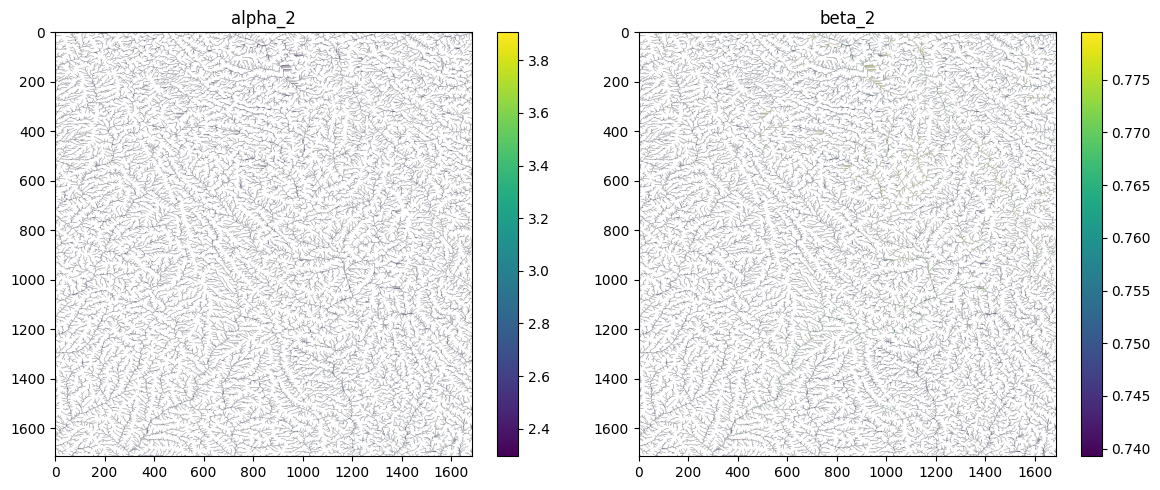

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(alpha_grid, cmap="viridis")
axes[0].set_title("alpha_2")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(beta_grid, cmap="viridis")
axes[1].set_title("beta_2")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()
